<a href="https://colab.research.google.com/github/EnesKok20/cepte-vet/blob/main/notebooks/07_test_degerlendirme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07 – Test Seti Değerlendirmesi

**Amaç:** 05 (imgsz=224) ve 06 (imgsz=320) modellerini, eğitimde hiç görülmemiş test seti üzerinde karşılaştırmak.

**Ölçütler:**
- Accuracy (genel doğruluk) – hedef ≥ %85
- Lumpy recall (gerçek hastaların kaçını yakaladık) – en kritik ölçüt
- Confusion matrix
- Eşik ayarı ile recall iyileştirmesi

**Not:** Sistem teşhis koymaz, ön tespit yapar ve veterinere yönlendirir.

In [1]:
# Drive'ı bağla ve Ultralytics'i kur
from google.colab import drive
drive.mount('/content/drive')

!pip install -q ultralytics

import os, glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [2]:
# Drive'daki tüm best.pt dosyalarını bul
print('=== best.pt dosyaları ===')
for p in glob.glob('/content/drive/MyDrive/**/best.pt', recursive=True):
    print(p)

# İçinde 'test' adında klasör olan yerleri bul
print('\n=== test klasörleri ===')
for p in glob.glob('/content/drive/MyDrive/**/test', recursive=True):
    if os.path.isdir(p):
        print(p, '->', os.listdir(p))

=== best.pt dosyaları ===
/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/runs/baseline_yolo11n/weights/best.pt
/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/runs/yolo11n_320/weights/best.pt

=== test klasörleri ===


In [3]:
ANA = '/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik'

# Veri setini zip'ten aç (06'daki ile aynı)
!mkdir -p /content/data && cp "{ANA}/hazir/cattle_cls.zip" /content/data/
!cd /content/data && unzip -q -o cattle_cls.zip

# test klasörünü otomatik bul
TEST_DIR = [p for p in glob.glob('/content/data/**/test', recursive=True) if os.path.isdir(p)][0]
print('Test klasörü:', TEST_DIR)
for sinif in sorted(os.listdir(TEST_DIR)):
    print(f'  {sinif:10}: {len(os.listdir(os.path.join(TEST_DIR, sinif)))} fotoğraf')

# runs içindeki modelleri listele
print('\n=== Modeller ===')
for p in sorted(glob.glob(f'{ANA}/runs/**/best.pt', recursive=True)):
    print(p)

Test klasörü: /content/data/cattle_cls/test
  healthy   : 276 fotoğraf
  lumpy     : 183 fotoğraf

=== Modeller ===
/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/runs/baseline_yolo11n/weights/best.pt
/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/runs/yolo11n_320/weights/best.pt


## 2. Modellerin test seti tahminleri
Her fotoğraf için modelin verdiği **lumpy olasılığını** kaydediyoruz. Tahmini (hasta / sağlıklı) sonradan bu olasılık ve seçtiğimiz eşik ile belirleyeceğiz.

In [4]:
MODELLER = {
    'baseline_224': f'{ANA}/runs/baseline_yolo11n/weights/best.pt',
    'yolo11n_320':  f'{ANA}/runs/yolo11n_320/weights/best.pt',
}

# Test fotoğrafları ve gerçek etiketleri (1 = lumpy, 0 = healthy)
yollar, gercek = [], []
for sinif in ['healthy', 'lumpy']:
    for p in sorted(glob.glob(os.path.join(TEST_DIR, sinif, '*'))):
        yollar.append(p)
        gercek.append(1 if sinif == 'lumpy' else 0)
gercek = np.array(gercek)

def lumpy_olasiliklari(model_yolu):
    model = YOLO(model_yolu)
    imgsz = model.overrides.get('imgsz', 224)   # model hangi boyutla eğitildiyse onu kullan
    lumpy_idx = [k for k, v in model.names.items() if v == 'lumpy'][0]
    olas = []
    for i in range(0, len(yollar), 64):
        for r in model.predict(yollar[i:i+64], imgsz=imgsz, verbose=False):
            olas.append(r.probs.data[lumpy_idx].item())
    print(f'{os.path.basename(os.path.dirname(os.path.dirname(model_yolu)))}: imgsz={imgsz}, {len(olas)} tahmin')
    return np.array(olas)

OLASILIK = {ad: lumpy_olasiliklari(yol) for ad, yol in MODELLER.items()}

baseline_yolo11n: imgsz=224, 459 tahmin
yolo11n_320: imgsz=320, 459 tahmin


## 3. Metrikler ve confusion matrix (eşik = 0.5)
Varsayılan kural: lumpy olasılığı ≥ 0.5 ise "hasta" kabul edilir.

Model            Accuracy   Recall  Precision  Specif.  Kaçan  Y.Alarm
baseline_224        0.913    0.880      0.899    0.935     22       18
yolo11n_320         0.930    0.902      0.922    0.949     18       14


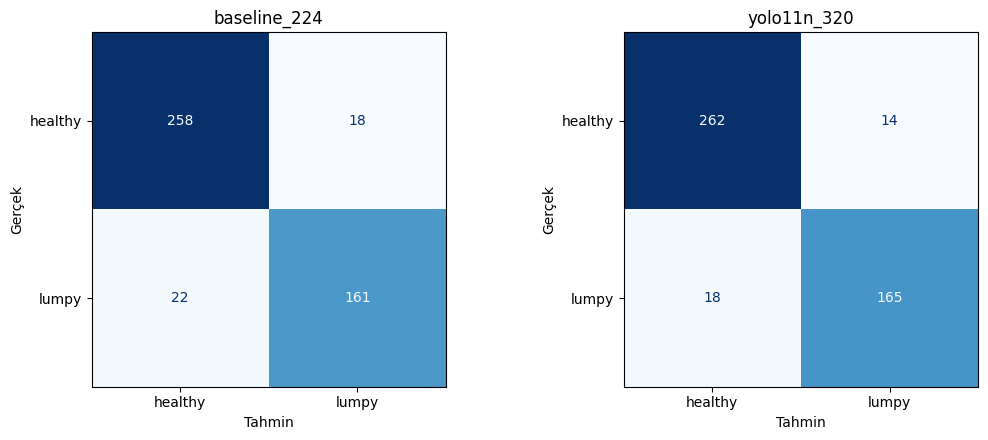

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def metrikler(olas, esik=0.5):
    tahmin = (olas >= esik).astype(int)
    tn, fp, fn, tp = confusion_matrix(gercek, tahmin).ravel()
    return {
        'accuracy':    (tp + tn) / len(gercek),
        'recall':      tp / (tp + fn),   # hastaların kaçını yakaladık
        'precision':   tp / (tp + fp),   # "hasta" dediklerimizin kaçı gerçekten hasta
        'specificity': tn / (tn + fp),   # sağlıklıların kaçını doğru bildik
        'kacan_hasta': fn,
        'yanlis_alarm': fp,
    }

# Tablo
print(f'{"Model":15}{"Accuracy":>10}{"Recall":>9}{"Precision":>11}{"Specif.":>9}{"Kaçan":>7}{"Y.Alarm":>9}')
for ad, olas in OLASILIK.items():
    m = metrikler(olas)
    print(f'{ad:15}{m["accuracy"]:>10.3f}{m["recall"]:>9.3f}{m["precision"]:>11.3f}'
          f'{m["specificity"]:>9.3f}{m["kacan_hasta"]:>7}{m["yanlis_alarm"]:>9}')

# Confusion matrix'ler yan yana
fig, eksen = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (ad, olas) in zip(eksen, OLASILIK.items()):
    cm = confusion_matrix(gercek, (olas >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=['healthy', 'lumpy']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(ad); ax.set_xlabel('Tahmin'); ax.set_ylabel('Gerçek')
plt.tight_layout()

# Rapor için Drive'a kaydet
os.makedirs(f'{ANA}/raporlar', exist_ok=True)
plt.savefig(f'{ANA}/raporlar/07_confusion_matrix.png', dpi=150)
plt.show()

## 4. Eşik ayarı (val seti üzerinde)
Amaç: hasta kaçırmayı azaltmak. Eşik val setinde seçilir, test setine sadece bir kez uygulanır (veri sızıntısını önlemek için).


In [6]:
# val klasörünü bul
VAL_DIR = [p for p in glob.glob('/content/data/**/val*', recursive=True) if os.path.isdir(p)][0]
print('Val klasörü:', VAL_DIR)

# val fotoğrafları ve etiketleri
val_yollar, val_gercek = [], []
for sinif in ['healthy', 'lumpy']:
    for p in sorted(glob.glob(os.path.join(VAL_DIR, sinif, '*'))):
        val_yollar.append(p)
        val_gercek.append(1 if sinif == 'lumpy' else 0)
val_gercek = np.array(val_gercek)
print(f'healthy: {(val_gercek==0).sum()}, lumpy: {(val_gercek==1).sum()}\n')

# 320 modeliyle val olasılıkları
model = YOLO(MODELLER['yolo11n_320'])
lumpy_idx = [k for k, v in model.names.items() if v == 'lumpy'][0]
val_olas = []
for i in range(0, len(val_yollar), 64):
    for r in model.predict(val_yollar[i:i+64], imgsz=320, verbose=False):
        val_olas.append(r.probs.data[lumpy_idx].item())
val_olas = np.array(val_olas)

# Eşik taraması
print(f'{"Eşik":>5}{"Recall":>9}{"Precision":>11}{"Accuracy":>10}{"Kaçan":>7}{"Y.Alarm":>9}')
for esik in [0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2, 0.15, 0.1]:
    t = (val_olas >= esik).astype(int)
    tp = ((t==1)&(val_gercek==1)).sum(); fn = ((t==0)&(val_gercek==1)).sum()
    fp = ((t==1)&(val_gercek==0)).sum(); acc = (t==val_gercek).mean()
    print(f'{esik:>5}{tp/(tp+fn):>9.3f}{tp/(tp+fp):>11.3f}{acc:>10.3f}{fn:>7}{fp:>9}')

Val klasörü: /content/data/cattle_cls/val
healthy: 276, lumpy: 182

 Eşik   Recall  Precision  Accuracy  Kaçan  Y.Alarm
  0.5    0.940      0.950     0.956     11        9
 0.45    0.940      0.940     0.952     11       11
  0.4    0.945      0.940     0.954     10       11
 0.35    0.956      0.921     0.950      8       15
  0.3    0.956      0.911     0.945      8       17
 0.25    0.962      0.907     0.945      7       18
  0.2    0.962      0.902     0.943      7       19
 0.15    0.962      0.888     0.937      7       22
  0.1    0.978      0.873     0.934      4       26


**Seçilen eşik: 0.35.** Val setinde kaçan hasta 11 → 8'e düştü, accuracy %95 seviyesinde kaldı. 0.3 aynı recall'u daha fazla yanlış alarmla verdiği için elendi.

## 5. Seçilen eşiğin test setinde değerlendirilmesi

              Accuracy   Recall  Precision  Kaçan  Y.Alarm
Eşik 0.50        0.930    0.902      0.922     18       14
Eşik 0.35        0.926    0.923      0.894     14       20


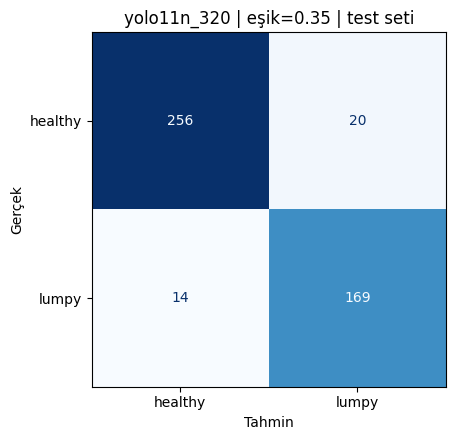

In [7]:
ESIK = 0.35
olas = OLASILIK['yolo11n_320']

print(f'{"":12}{"Accuracy":>10}{"Recall":>9}{"Precision":>11}{"Kaçan":>7}{"Y.Alarm":>9}')
for etiket, e in [('Eşik 0.50', 0.5), (f'Eşik {ESIK}', ESIK)]:
    m = metrikler(olas, e)
    print(f'{etiket:12}{m["accuracy"]:>10.3f}{m["recall"]:>9.3f}{m["precision"]:>11.3f}'
          f'{m["kacan_hasta"]:>7}{m["yanlis_alarm"]:>9}')

# Nihai confusion matrix
cm = confusion_matrix(gercek, (olas >= ESIK).astype(int))
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=['healthy', 'lumpy']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'yolo11n_320 | eşik={ESIK} | test seti')
ax.set_xlabel('Tahmin'); ax.set_ylabel('Gerçek')
plt.tight_layout()
plt.savefig(f'{ANA}/raporlar/07_nihai_confusion_matrix.png', dpi=150)
plt.show()

## 6. Hata analizi
Eşik 0.35'te kaçan hastalar ve yanlış alarmlar. Amaç: etiket hatası, kötü fotoğraf veya modelin zayıf olduğu durumları tespit etmek.

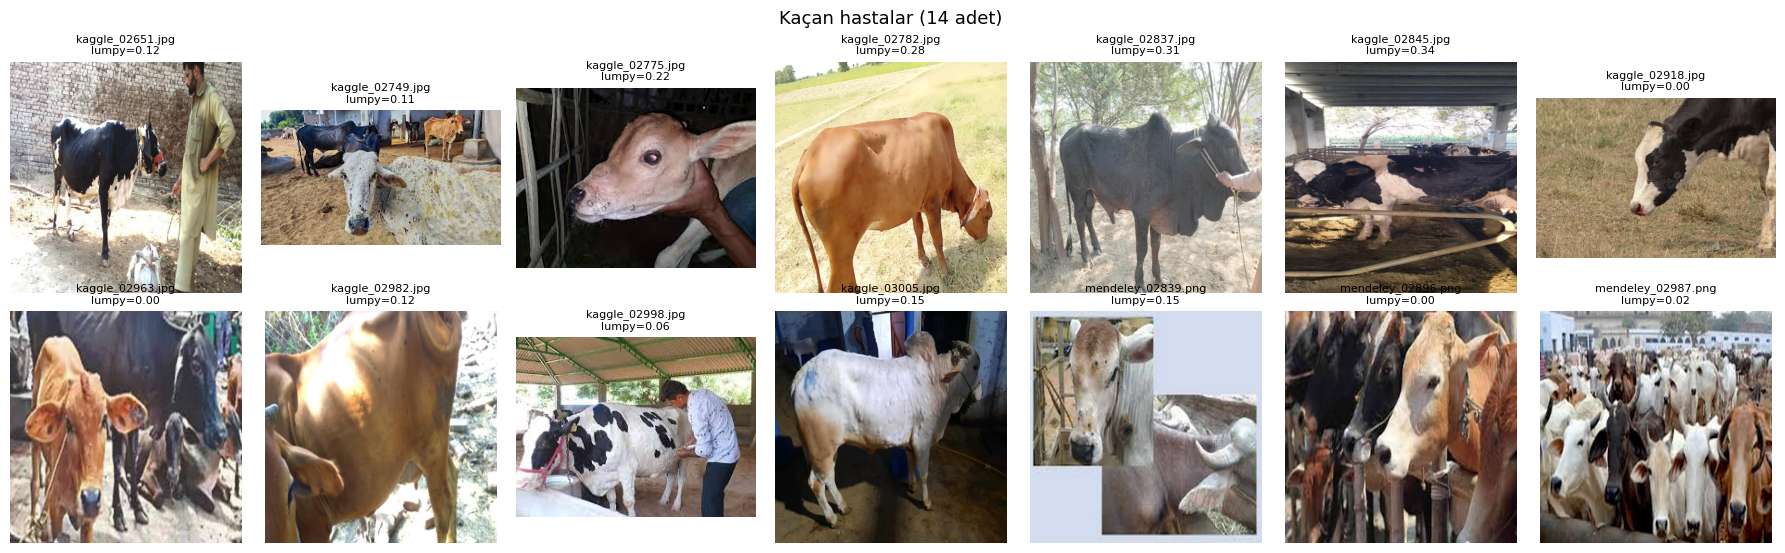

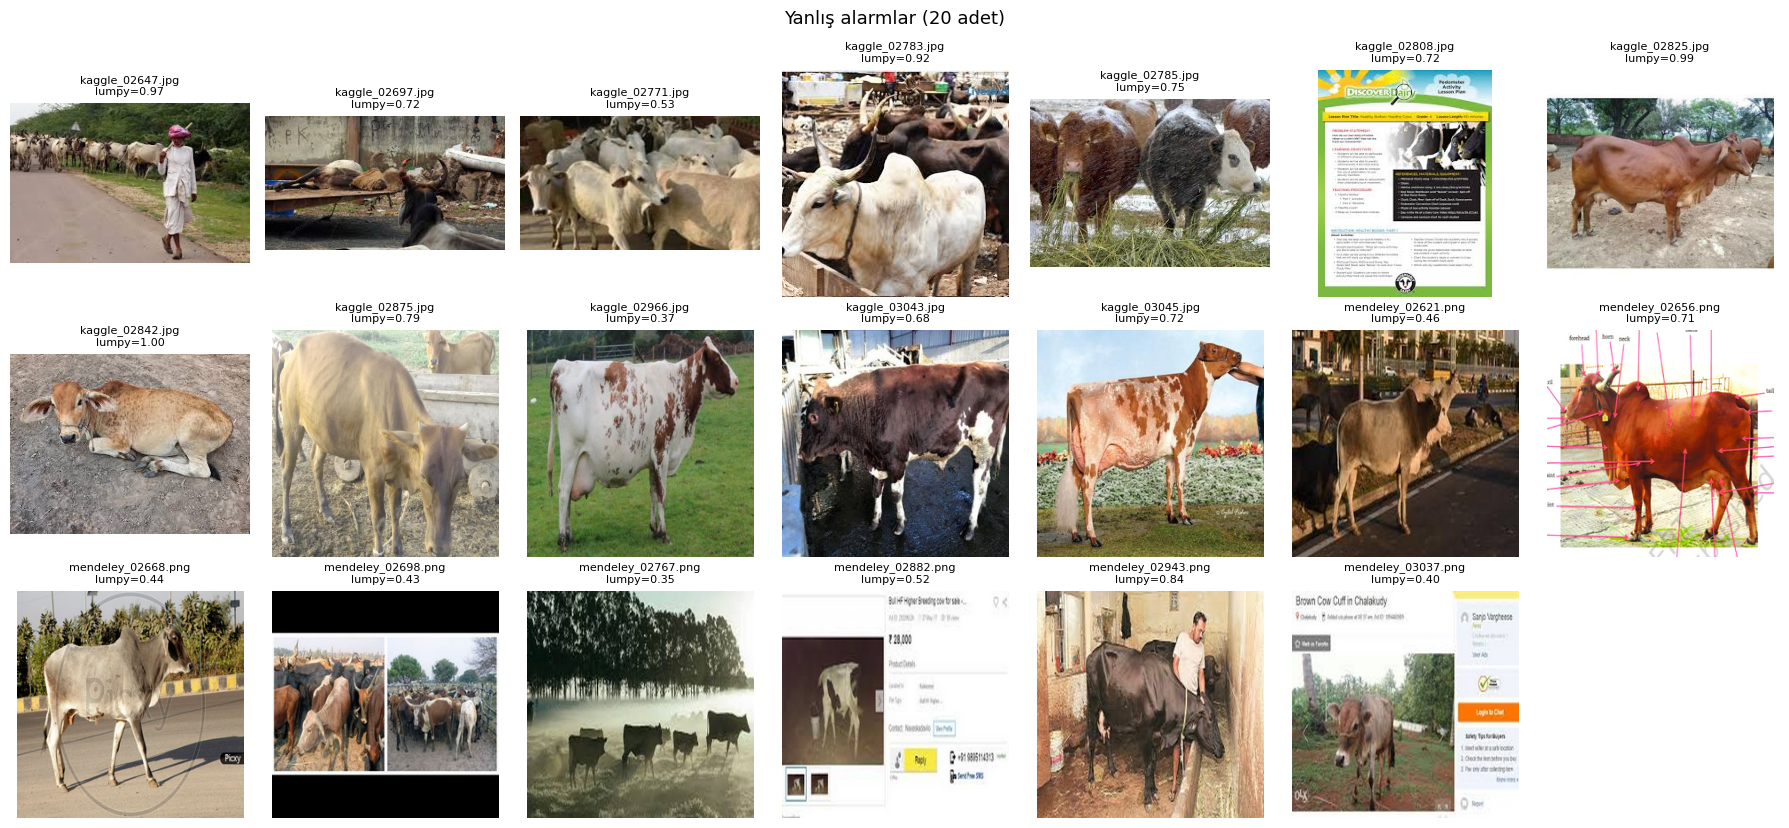

In [8]:
tahmin = (olas >= ESIK).astype(int)
kacan  = [i for i in range(len(yollar)) if gercek[i] == 1 and tahmin[i] == 0]
alarm  = [i for i in range(len(yollar)) if gercek[i] == 0 and tahmin[i] == 1]

def goster(indeksler, baslik, dosya):
    n = len(indeksler); sutun = 7; satir = int(np.ceil(n / sutun))
    fig, eksen = plt.subplots(satir, sutun, figsize=(18, 2.8 * satir), squeeze=False)
    for ax in eksen.flat: ax.axis('off')
    for ax, i in zip(eksen.flat, indeksler):
        ax.imshow(Image.open(yollar[i]).convert('RGB'))
        ax.set_title(f'{os.path.basename(yollar[i])}\nlumpy={olas[i]:.2f}', fontsize=8)
    fig.suptitle(f'{baslik} ({n} adet)', fontsize=13)
    plt.tight_layout()
    plt.savefig(f'{ANA}/raporlar/{dosya}', dpi=120)
    plt.show()

goster(kacan, 'Kaçan hastalar', '07_kacan_hastalar.png')
goster(alarm, 'Yanlış alarmlar', '07_yanlis_alarmlar.png')

## 7. Sonuç
| Model | Eşik | Accuracy | Lumpy Recall | Precision | Kaçan | Y. Alarm |
|---|---|---|---|---|---|---|
| baseline (224) | 0.50 | 0.913 | 0.880 | 0.899 | 22 | 18 |
| yolo11n_320 | 0.50 | 0.930 | 0.902 | 0.922 | 18 | 14 |
| **yolo11n_320** | **0.35** | **0.926** | **0.923** | **0.894** | **14** | **20** |

- Görüntü boyutunun 224'ten 320'ye çıkarılması tüm ölçütleri iyileştirdi. Uzaktan çekilmiş fotoğraflarda küçük nodüller daha iyi görülüyor.
- Eşik val setinde seçildi (0.35), test setine bir kez uygulandı. Recall %90,2'den %92,3'e çıktı.
- Formdaki %85 accuracy hedefi aşıldı (%92,6).
- **Seçilen model:** yolo11n_320, eşik 0.35

**Sonraki adımlar:** etiket kontrolü (hata analizindeki şüpheli örnekler), imgsz=448 denemesi, modelin FastAPI servisine taşınması.